# Insol Prediction for PCC Cement (Insilo 1, sheet CM02PCC)

Predict the daily **Insol** (insoluble residue, %) of Portland Composite Cement from its chemical
composition (oxides), fineness (Blaine) and lagged values, using a strictly time-aware workflow.

**Pipeline**

| # | Section | What happens |
|---|---------|--------------|
| 1 | Setup | imports, paths, constants |
| 2 | Helper functions | everything reusable lives here |
| 3 | Load & clean | rebuild dates, clean values |
| 4 | Split & impute | chronological 80/20 split, KNN imputation fitted on train only |
| 5 | EDA | distributions, normality, correlation |
| 6 | Features & model selection | lag features, `TimeSeriesSplit` over 9 regressors |
| 7 | Test evaluation | best model vs. naive baselines, residual bias by month |
| 8 | EWMA residual correction | baseline version, span chosen by CV |
| 9 | Tuning & improved correction | tuned linear models, out-of-fold residuals, significance tests |
| 10 | Huber regression | **final model: Huber + EWMA(7)** and final measurement |
| 11 | Final figure | actual vs. predicted |
| 12 | Inference | next-day and hourly (per-row) prediction |
| 13 | Save the model | one `.joblib` bundle |

> To run **Insilo 2**, change only `SILO`, `EXCEL_FILE` and `SHEET_NAME` in the configuration cell.

## 1. Setup

In [9]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
import math
import os
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2, shapiro, wilcoxon
from sklearn.base import clone
from sklearn.ensemble import (ExtraTreesRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, RandomForestRegressor)
from sklearn.impute import KNNImputer
from sklearn.linear_model import (ElasticNet, HuberRegressor, LinearRegression,
                                  Lasso, Ridge)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)

### Configuration

All paths and constants are defined here and nowhere else. **Data files are not part of the repository**;
put them in `DATA_DIR` (default `./data`) or set the `INSOL_DATA_DIR` environment variable.

*Google Colab:* uncomment the three lines in the next cell to read from Drive.

In [11]:
# --- Google Colab only (uncomment) --------------------------------------
# from google.colab import drive
# drive.mount("/content/drive")
# os.environ["INSOL_DATA_DIR"] = "/content/drive/MyDrive"
# ------------------------------------------------------------------------

DATA_DIR = Path(os.environ.get("INSOL_DATA_DIR", "data"))
OUTPUT_DIR = Path(os.environ.get("INSOL_OUTPUT_DIR", "outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- Change these for Insilo 2 ----------------------------------------
SILO = "insilo1"
EXCEL_FILE = DATA_DIR / "new data semen.xlsx"             # daily lab data
SHEET_NAME = "CM02PCC"
# -----------------------------------------------------------------------
HOURLY_CSV = DATA_DIR / "QC_hourly.csv"                   # optional: hourly QC export (needs SamplingLocalTime)
NEW_DAILY_FILE = None                                     # optional: daily data after the last date in EXCEL_FILE
#   NEW_DAILY_FILE = DATA_DIR / "data_baru.xlsx"
#   columns: Tanggal, SiO2, Al203, Fe203, CaO, MgO, SO3, Residu, Blaine, P2O5, Na2O, K2O, Insol

# Column names are kept exactly as they appear in the source files (note "Al203"/"Fe203" use a zero).
FEATURES = ["SiO2", "Al203", "Fe203", "CaO", "MgO", "SO3",
            "Residu", "Blaine", "P2O5", "Na2O", "K2O"]
TARGET = "Insol"
LAG_FEATURES = ["SiO2", "Al203", "Fe203", "CaO", "SO3", "Blaine", "Na2O", "K2O"]   # the 8 "core" oxides
LAG_LIST = [1, 2, 3, 5, 10]
MAX_LAG = max(LAG_LIST)

TRAIN_FRACTION = 0.8
EWMA_SPAN = 7             # span used by the final model
APPLY_DOMAIN_RULES = False  # True: CaO < 40 and Al2O3 < 1 are input errors (set to NaN, then imputed)
TOLERANCE = 1.0           # a day counts as "good" when |error| <= TOLERANCE
RANDOM_STATE = 42
CV_SPLITS = 5

## 2. Helper functions

Grouped by purpose. Nothing in this section reads data or produces output.

### 2.1 Data preparation

In [12]:
MONTH_MAP = {"JAN": 1, "FEB": 2, "MAR": 3, "APR": 4, "MEI": 5, "JUN": 6,
             "JUL": 7, "AGS": 8, "SEP": 9, "OKT": 10, "NOV": 11, "DES": 12}


def reconstruct_dates(df):
    """Build a real date from the sheet's BULAN ('JAN', 'FEB', ... or a real date) and 'Tgl.' columns.

    A real date only appears on the first row of each year and carries the year. Only genuine date
    objects are used as year markers: to_datetime on the whole column can turn 'JAN'/'MAR' into
    dates with a nonsense year in recent pandas versions.
    """
    month = df["BULAN"].astype(str).str.strip().str.upper().str[:3].map(MONTH_MAP)
    is_date = df["BULAN"].map(lambda v: hasattr(v, "year"))
    marker = pd.to_datetime(df["BULAN"].where(is_date), errors="coerce")

    month = month.fillna(marker.dt.month)
    year = marker.dt.year.ffill()
    return pd.to_datetime(
        {"year": year, "month": month, "day": pd.to_numeric(df["Tgl."], errors="coerce")},
        errors="coerce",
    )


def clean_raw(df):
    """'-' / '--' placeholders become NaN, measurement columns become numeric."""
    df = df.replace(r"^\s*(--|-)\s*$", np.nan, regex=True)
    for col in FEATURES + [TARGET]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


def apply_domain_rules(df, verbose=False):
    """Physically impossible PCC values are input errors: CaO < 40, Al2O3 < 1 (set to NaN)."""
    df = df.copy()
    bad_cao, bad_al = df["CaO"] < 40, df["Al203"] < 1
    if verbose:
        print(f"Domain rules: {int(bad_cao.sum())} CaO and {int(bad_al.sum())} Al203 values set to NaN")
    df.loc[bad_cao, "CaO"] = np.nan
    df.loc[bad_al, "Al203"] = np.nan
    return df


def chronological_split(df, train_fraction=TRAIN_FRACTION):
    """Boolean train mask and cut date. df must be sorted by date."""
    cut_date = df["Tanggal"].iloc[int(len(df) * train_fraction)]
    return df["Tanggal"] < cut_date, cut_date


def impute(X, scaler, imputer):
    """KNN-impute with a scaler/imputer fitted on TRAIN (features are standardised first, then restored)."""
    X = X.reindex(columns=FEATURES)
    return pd.DataFrame(
        scaler.inverse_transform(imputer.transform(scaler.transform(X))),
        columns=FEATURES, index=X.index)


def add_lags(X):
    """Append lagged copies of LAG_FEATURES. Rows must be in time order."""
    lags = {f"{c}_lag{L}": X[c].shift(L) for c in LAG_FEATURES for L in LAG_LIST}
    return pd.concat([X, pd.DataFrame(lags, index=X.index)], axis=1)

### 2.2 Models and metrics

In [13]:
def regression_metrics(name, y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    abs_err = np.abs(y_true - y_pred)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        f"% days error<={TOLERANCE:g}": (abs_err <= TOLERANCE).mean() * 100,
    }


def scaled(estimator):
    return Pipeline([("scaler", StandardScaler()), ("model", estimator)])


def candidate_models():
    """Fresh (unfitted) models compared in section 6."""
    return {
        "Linear Regression": scaled(LinearRegression()),
        "Ridge": scaled(Ridge(alpha=1.0)),
        "Lasso": scaled(Lasso(alpha=0.01)),
        "ElasticNet": scaled(ElasticNet(alpha=0.01, l1_ratio=0.5)),
        "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
        "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
        "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    }


def make_huber():
    """Huber loss: robust to occasional spikes in Insol."""
    return scaled(HuberRegressor(epsilon=1.35, alpha=0.01, max_iter=2000))


TUNING_CANDIDATES = {
    "Ridge": (Ridge(), {"m__alpha": np.logspace(-1, 3, 30)}),
    "Lasso": (Lasso(max_iter=50000), {"m__alpha": np.logspace(-4, 0.5, 30)}),
    "ElasticNet": (ElasticNet(max_iter=50000),
                   {"m__alpha": np.logspace(-4, 0.5, 30), "m__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]}),
}


def tune_linear(name, X, y, cv):
    """Grid search (MAE, chronological CV) for Ridge / Lasso / ElasticNet."""
    estimator, grid = TUNING_CANDIDATES[name]
    pipe = Pipeline([("s", StandardScaler()), ("m", clone(estimator))])
    return GridSearchCV(pipe, grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1).fit(X, y)

### 2.3 Residual correction

In [14]:
def sequential_residual_correction(y_true, y_pred, span, initial_residuals=None):
    """EWMA residual correction (baseline version, used by sections 7, 8, 10 and 11).

    For prediction t: correction = EWMA(residuals before t). Once the actual value is known:
    residual_t = actual_t - CORRECTED prediction_t. Because the corrected residual is fed back, a constant
    bias b is only corrected to about b/2 (see the simulation in section 9).

    initial_residuals: residuals known before the prediction period (e.g. the model's train residuals).
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    history = [] if initial_residuals is None else list(np.asarray(initial_residuals, dtype=float))

    corrected = []
    for i in range(len(y_pred)):
        if len(history) >= 3:
            correction = pd.Series(history).ewm(span=span, min_periods=3, adjust=False).mean().iloc[-1]
        else:
            correction = 0.0
        new_pred = y_pred[i] + correction
        corrected.append(new_pred)
        history.append(y_true[i] - new_pred)
    return np.asarray(corrected)


def ewma_correction(raw_residuals, span, delay=0, min_periods=3):
    """Improved version (section 9): EWMA of the RAW model residuals (actual - model prediction).

    The correction for day t uses residuals up to day t - 1 - delay, so there is no leakage.
    Returns one correction per day, to be ADDED to the model prediction.
    """
    s = pd.Series(np.asarray(raw_residuals, dtype=float))
    return (s.ewm(span=span, adjust=False, min_periods=min_periods).mean()
             .shift(1 + delay).fillna(0.0).values)


def latest_ewma_offset(raw_residuals, span):
    """Single correction for the NEXT day, from raw model residuals (used at inference)."""
    return float(pd.Series(np.asarray(raw_residuals, dtype=float))
                 .ewm(span=span, min_periods=3, adjust=False).mean().iloc[-1])

### 2.4 Statistics and reporting

In [15]:
def monthly_report(dates, y_true, predictions):
    """Bias (mean residual), MAE and RMSE per calendar month for one or more prediction series.

    residual = actual - prediction; positive = under-prediction, negative = over-prediction.
    """
    frame = pd.DataFrame({"Month": pd.Series(dates).dt.to_period("M").values})
    for name, pred in predictions.items():
        frame[name] = np.asarray(y_true, float) - np.asarray(pred, float)

    grouped = frame.groupby("Month")
    out = pd.DataFrame({"n": grouped.size()})
    for name in predictions:
        out[f"bias_{name}"] = grouped[name].mean()
        out[f"MAE_{name}"] = grouped[name].apply(lambda x: np.mean(np.abs(x)))
        out[f"RMSE_{name}"] = grouped[name].apply(lambda x: np.sqrt(np.mean(x ** 2)))
    return out


def acf_manual(x, nlags):
    x = np.asarray(x, float) - np.mean(x)
    denom = np.sum(x ** 2)
    return np.array([np.sum(x[:len(x) - k] * x[k:]) / denom for k in range(nlags + 1)])


def ljung_box(x, lags=(5, 10, 20)):
    """p-values of the Ljung-Box test (small p = autocorrelation remains)."""
    n, r = len(x), acf_manual(x, max(lags))
    return {h: chi2.sf(n * (n + 2) * np.sum(r[1:h + 1] ** 2 / (n - np.arange(1, h + 1))), h) for h in lags}

### 2.5 Plot helpers

In [16]:
def grid_axes(n_plots, ncols=2, row_height=3.4):
    """Create a grid just big enough for n_plots; returns (fig, flat list of the axes to use)."""
    nrows = math.ceil(n_plots / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, row_height * nrows))
    axes = np.atleast_1d(axes).flatten()
    for ax in axes[n_plots:]:
        fig.delaxes(ax)
    return fig, axes[:n_plots]


def plot_monthly_bias(report, names, title):
    plt.figure(figsize=(15, 5))
    for name in names:
        plt.plot(report.index.astype(str), report[f"bias_{name}"], marker="o", label=name)
    plt.axhline(0, linestyle="--", color="k", lw=0.8)
    plt.xticks(rotation=45)
    plt.ylabel("Mean residual (actual - prediction)")
    plt.title(title)
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


def plot_actual_vs_predicted(dates, y_actual, p_main, p_raw, label, raw_label="Huber", save_as=None):
    """3-panel figure: time series with tolerance band, scatter, residuals with rolling mean."""
    dates = pd.to_datetime(pd.Series(dates)).reset_index(drop=True)
    y = np.asarray(y_actual, float)
    p = np.asarray(p_main, float)
    err = y - p
    outside = np.abs(err) > TOLERANCE

    m = regression_metrics(label, y, p)
    print(f"{label}: MAE={m['MAE']:.3f}  RMSE={m['RMSE']:.3f}  R2={m['R2']:.3f}  "
          f"error<={TOLERANCE:g}: {100 * (~outside).mean():.1f}%  ({outside.sum()} days outside)")
    print(f"Std of Insol in test = {y.std():.3f}")

    fig = plt.figure(figsize=(16, 11))
    gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1])
    ax1, ax2, ax3 = fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])

    ax1.plot(dates, y, color="black", lw=1.4, marker="o", ms=2.5, label="Actual")
    ax1.plot(dates, p_raw, color="tab:blue", lw=1, ls="--", alpha=0.5, label=raw_label)
    ax1.plot(dates, p, color="tab:red", lw=1.4, label=label)
    ax1.fill_between(dates, p - TOLERANCE, p + TOLERANCE, color="tab:red", alpha=0.10, label=f"Band +/-{TOLERANCE:g}")
    ax1.scatter(dates[outside], y[outside], s=45, facecolors="none", edgecolors="orange",
                linewidths=1.6, zorder=5, label=f"Outside +/-{TOLERANCE:g} ({outside.sum()} days)")
    ax1.set_title(f"Actual vs predicted Insol (test) | {label}: MAE={m['MAE']:.3f}, RMSE={m['RMSE']:.3f}, R2={m['R2']:.3f}")
    ax1.set_ylabel("Insol"); ax1.tick_params(axis="x", rotation=30)
    ax1.legend(ncol=3, fontsize=9); ax1.grid(alpha=0.3)

    lo, hi = min(y.min(), p.min()) - 0.3, max(y.max(), p.max()) + 0.3
    ax2.scatter(y[~outside], p[~outside], s=18, alpha=0.6, label=f"within +/-{TOLERANCE:g}")
    ax2.scatter(y[outside], p[outside], s=30, color="orange", label=f"outside +/-{TOLERANCE:g}")
    ax2.plot([lo, hi], [lo, hi], "k--", lw=1, label="ideal (y = x)")
    ax2.plot([lo, hi], [lo + TOLERANCE, hi + TOLERANCE], color="gray", lw=0.8, ls=":")
    ax2.plot([lo, hi], [lo - TOLERANCE, hi - TOLERANCE], color="gray", lw=0.8, ls=":")
    ax2.set_xlim(lo, hi); ax2.set_ylim(lo, hi)
    ax2.set_xlabel("Actual Insol"); ax2.set_ylabel("Predicted Insol")
    ax2.set_title("Actual vs predicted"); ax2.legend(fontsize=9); ax2.grid(alpha=0.3)

    ax3.bar(dates, err, width=1.0, color=np.where(outside, "orange", "tab:gray"), alpha=0.7)
    ax3.plot(dates, pd.Series(err).rolling(7, min_periods=3).mean(), color="tab:red", lw=1.6, label="7-day rolling mean")
    ax3.axhline(0, color="k", lw=0.8)
    ax3.axhline(TOLERANCE, color="gray", ls=":", lw=1); ax3.axhline(-TOLERANCE, color="gray", ls=":", lw=1)
    ax3.set_title("Residual (actual - predicted)"); ax3.tick_params(axis="x", rotation=30)
    ax3.legend(fontsize=9); ax3.grid(alpha=0.3)

    plt.tight_layout()
    if save_as is not None:
        plt.savefig(save_as, dpi=150, bbox_inches="tight")
    plt.show()

    worst = pd.DataFrame({"date": dates.dt.date, "actual": y.round(3), "predicted": p.round(3), "error": err.round(3)})[outside]
    return worst.reindex(worst["error"].abs().sort_values(ascending=False).index).head(15)

## 3. Load and clean

The sheet stores the month as text (`JAN`, `FEB`, ...) with a real date only on the first row of each
year, so the full date has to be rebuilt from `BULAN` + `Tgl.`.

In [17]:
raw = pd.read_excel(EXCEL_FILE, sheet_name=SHEET_NAME)
raw.columns = raw.columns.str.strip()
raw["Tanggal"] = reconstruct_dates(raw)

print("Invalid dates  :", raw["Tanggal"].isna().sum())
print("Duplicate dates:", raw["Tanggal"].duplicated().sum())
print("Date range     :", raw["Tanggal"].min().date(), "to", raw["Tanggal"].max().date())
raw.head()

Invalid dates  : 0
Duplicate dates: 0
Date range     : 2021-01-01 to 2026-09-19


,BULAN,FM,Tgl.,SiO2,Al203,Fe203,CaO,MgO,SO3,Residu,Blaine,Na2O,K2O,P2O5,Insol,Tanggal
0,2021-01-01 00:00:00,2,1,21.71597,5.69619,2.82933,55.93826,2.76125,1.73889,5.615744,440.170712,0.64764,0.69475,0.20111,11.880990,2021-01-01
1,JAN,2,2,21.23463,5.23724,2.83937,58.11739,2.53908,1.76032,4.376302,421.693049,0.53214,0.61369,0.19497,8.869686,2021-01-02
2,JAN,2,3,21.73000,0.42000,2.74000,56.56000,2.61000,1.66000,5.446927,448.744806,0.59,0.66000,0.19,11.384707,2021-01-03
3,JAN,2,4,21.91873,5.44701,2.80983,55.87961,3.14126,1.69655,5.756185,444.816740,0.63155,0.66729,0.19439,11.435134,2021-01-04
4,JAN,2,9,20.83012,5.42152,2.70620,56.94594,2.18258,1.70284,6.403013,496.851176,0.54614,0.61974,0.17758,10.483871,2021-01-09


In [18]:
df = clean_raw(raw)
if APPLY_DOMAIN_RULES:
    df = apply_domain_rules(df, verbose=True)
df = df.sort_values("Tanggal").reset_index(drop=True)

assert df[TARGET].notna().all(), "Empty Insol found: drop those rows AFTER the lags are built"
print("Missing values per column:")
print(df[FEATURES + [TARGET]].isna().sum())

Missing values per column:
SiO2        0
Al203       0
Fe203       0
CaO         0
MgO         0
SO3         0
Residu      0
Blaine      0
P2O5      449
Na2O        1
K2O         0
Insol       0
dtype: int64


## 4. Chronological split and imputation

First 80 % of the days = train, last 20 % = test. The scaler and KNN imputer are **fitted on train only**
and then applied to test.

In [19]:
is_train, cut_date = chronological_split(df)

X_train, X_test = df.loc[is_train, FEATURES], df.loc[~is_train, FEATURES]
y_train, y_test = df.loc[is_train, TARGET], df.loc[~is_train, TARGET]
dates_train, dates_test = df.loc[is_train, "Tanggal"], df.loc[~is_train, "Tanggal"].reset_index(drop=True)

print("Cut date:", cut_date.date())
print(f"Train: {dates_train.min().date()} to {dates_train.max().date()}  ({len(X_train)} rows)")
print(f"Test : {dates_test.min().date()} to {dates_test.max().date()}  ({len(X_test)} rows)")

Cut date: 2025-10-23
Train: 2021-01-01 to 2025-10-22  (896 rows)
Test : 2025-10-23 to 2026-09-19  (224 rows)


In [20]:
scaler_imp = StandardScaler().fit(X_train)
knn_imputer = KNNImputer(n_neighbors=5, weights="distance").fit(scaler_imp.transform(X_train))

X_train_imputed = impute(X_train, scaler_imp, knn_imputer)
X_test_imputed = impute(X_test, scaler_imp, knn_imputer)

print("Missing before:", int(X_train.isna().sum().sum()), "(train),", int(X_test.isna().sum().sum()), "(test)")
print("Missing after :", int(X_train_imputed.isna().sum().sum()), "(train),", int(X_test_imputed.isna().sum().sum()), "(test)")
print("\nCells filled by KNN (train + test):")
print((X_train.isna().sum() + X_test.isna().sum()).to_string())

Missing before: 379 (train), 71 (test)
Missing after : 0 (train), 0 (test)

Cells filled by KNN (train + test):
SiO2        0
Al203       0
Fe203       0
CaO         0
MgO         0
SO3         0
Residu      0
Blaine      0
P2O5      449
Na2O        1
K2O         0


## 5. Exploratory analysis (train data only)

Everything below is computed from the **imputed train set**, never from test. Nothing here feeds the model.

### 5.1 Distributions and normality

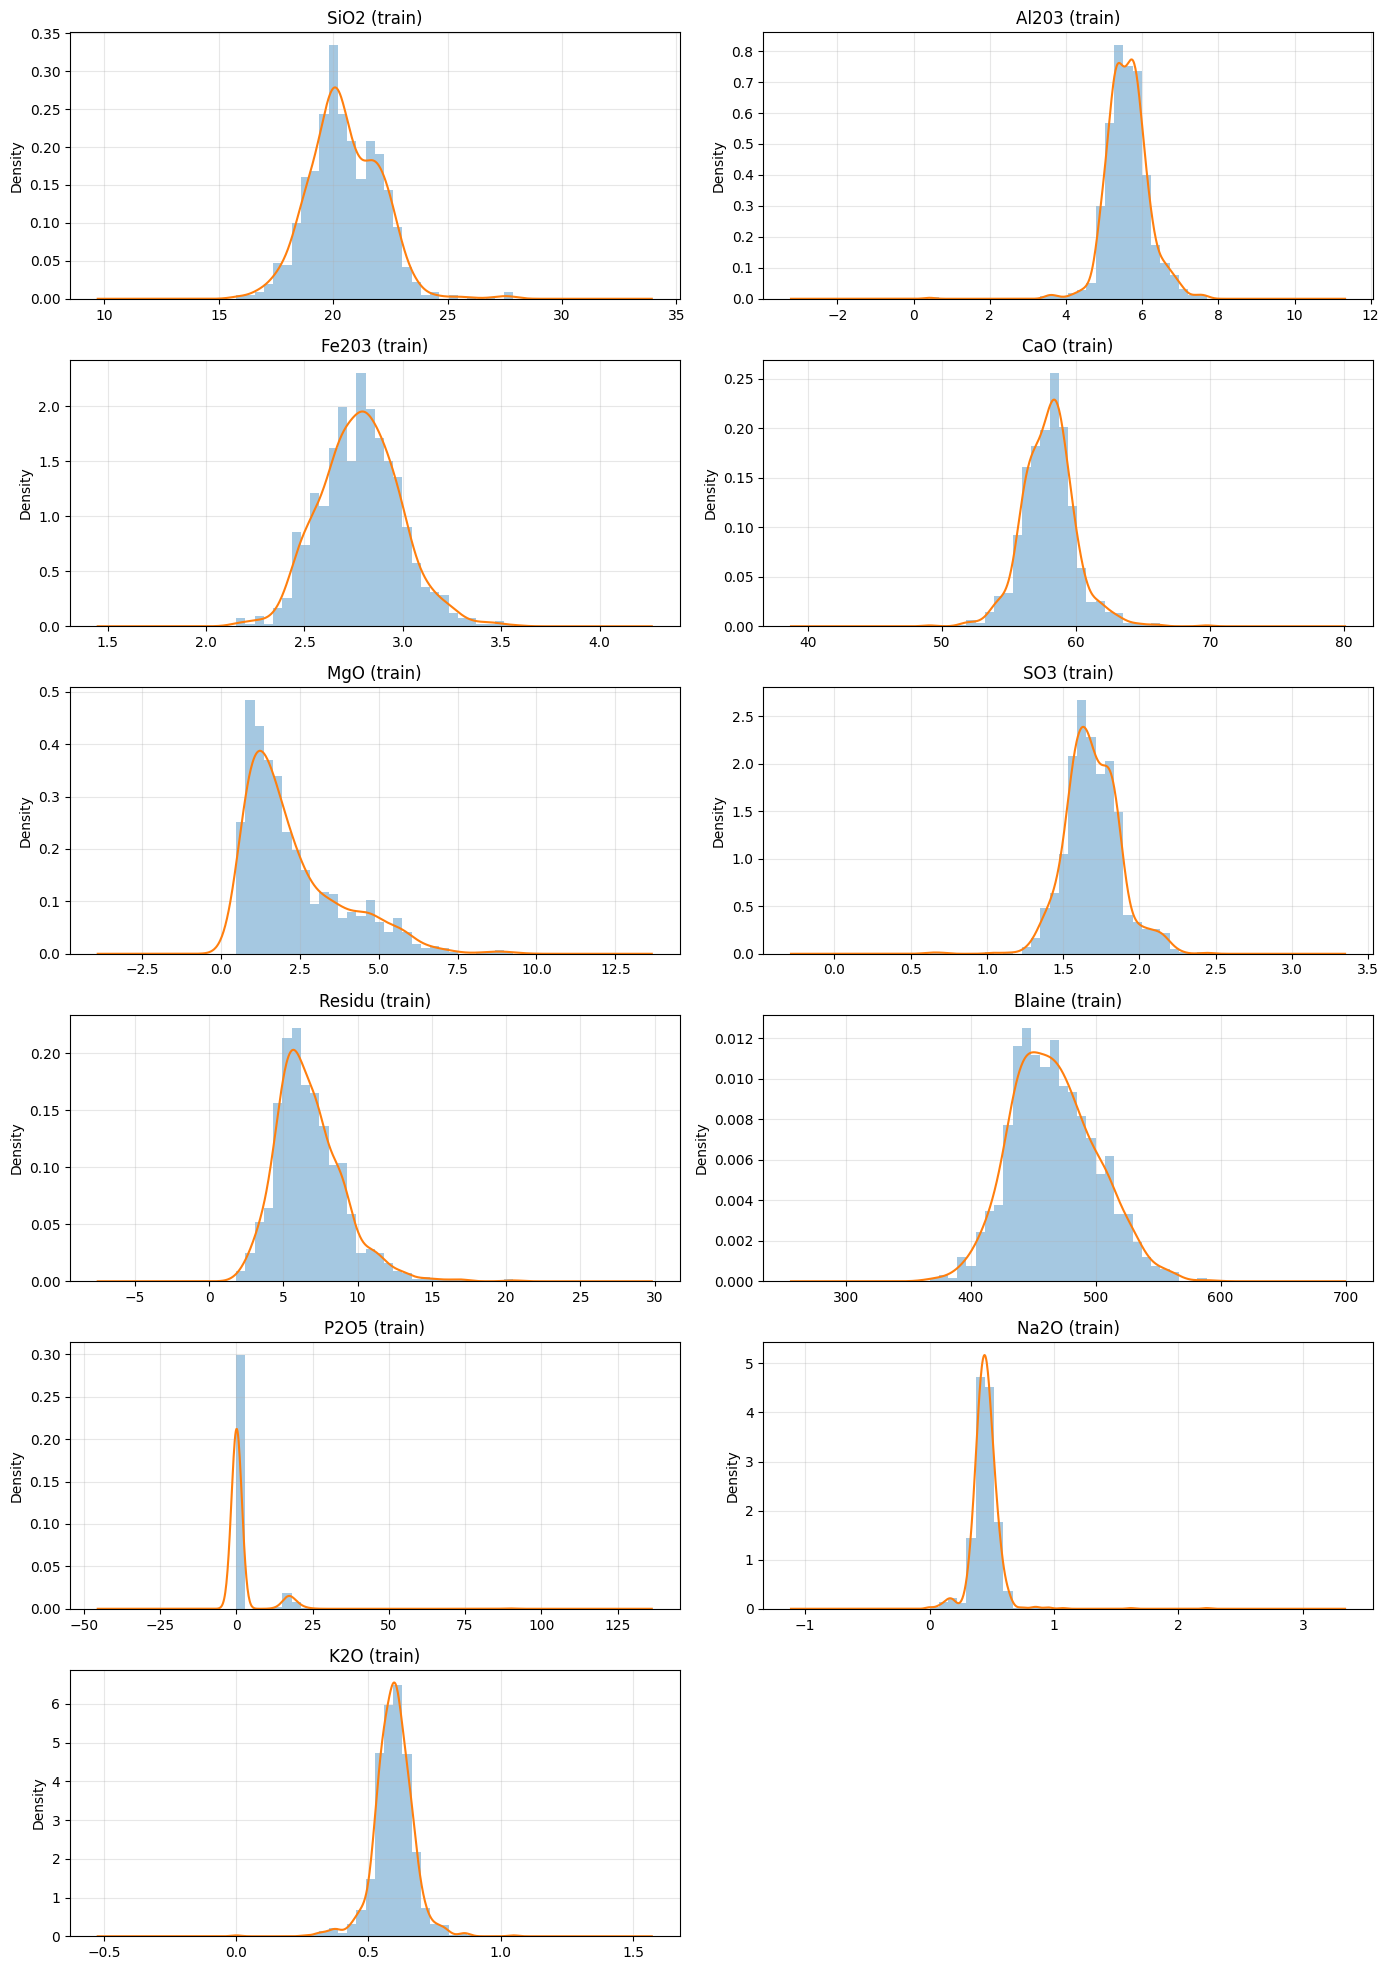

In [21]:
fig, axes = grid_axes(len(FEATURES), row_height=3.3)
for ax, col in zip(axes, FEATURES):
    X_train_imputed[col].plot(kind="hist", bins=30, density=True, alpha=0.4, ax=ax)
    X_train_imputed[col].plot(kind="kde", ax=ax)
    ax.set_title(f"{col} (train)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
shapiro_rows = []
for col in FEATURES:
    stat, p = shapiro(X_train_imputed[col])
    shapiro_rows.append({"Feature": col, "Statistic": stat, "p-value": p,
                         "Conclusion": "Normal" if p > 0.05 else "Not normal"})
pd.DataFrame(shapiro_rows)

,Feature,Statistic,p-value,Conclusion
0,SiO2,0.982423,6.578574e-09,Not normal
1,Al203,0.936099,3.788153e-19,Not normal
2,Fe203,0.995583,1.132909e-02,Not normal
3,CaO,0.973172,8.690868e-12,Not normal
4,MgO,0.864031,3.777705e-27,Not normal
5,SO3,0.971311,2.754129e-12,Not normal
6,Residu,0.947664,2.787258e-17,Not normal
7,Blaine,0.992778,2.403685e-04,Not normal
8,P2O5,0.301671,1.299600e-49,Not normal
9,Na2O,0.711574,1.335102e-36,Not normal


### 5.2 Target over time

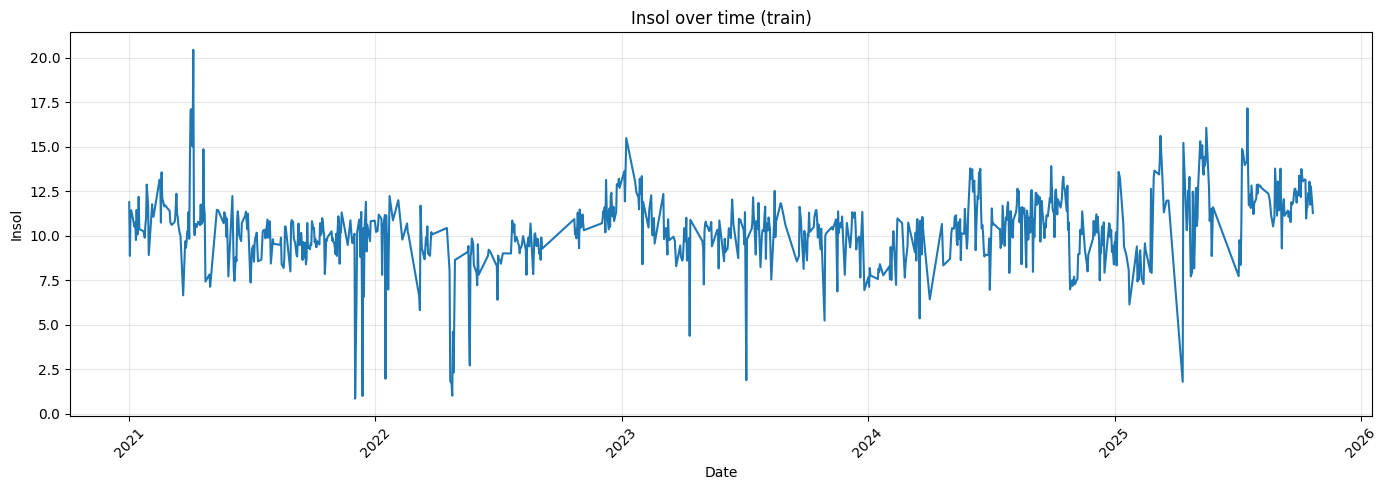

In [23]:
plt.figure(figsize=(14, 5))
plt.plot(dates_train, y_train)
plt.title("Insol over time (train)"); plt.xlabel("Date"); plt.ylabel("Insol")
plt.xticks(rotation=45); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 5.3 Correlation with Insol

Pearson correlation on the levels, and again after first-differencing. A feature that is correlated only
because both series share a trend loses correlation after differencing; one that keeps it is related
day to day as well.

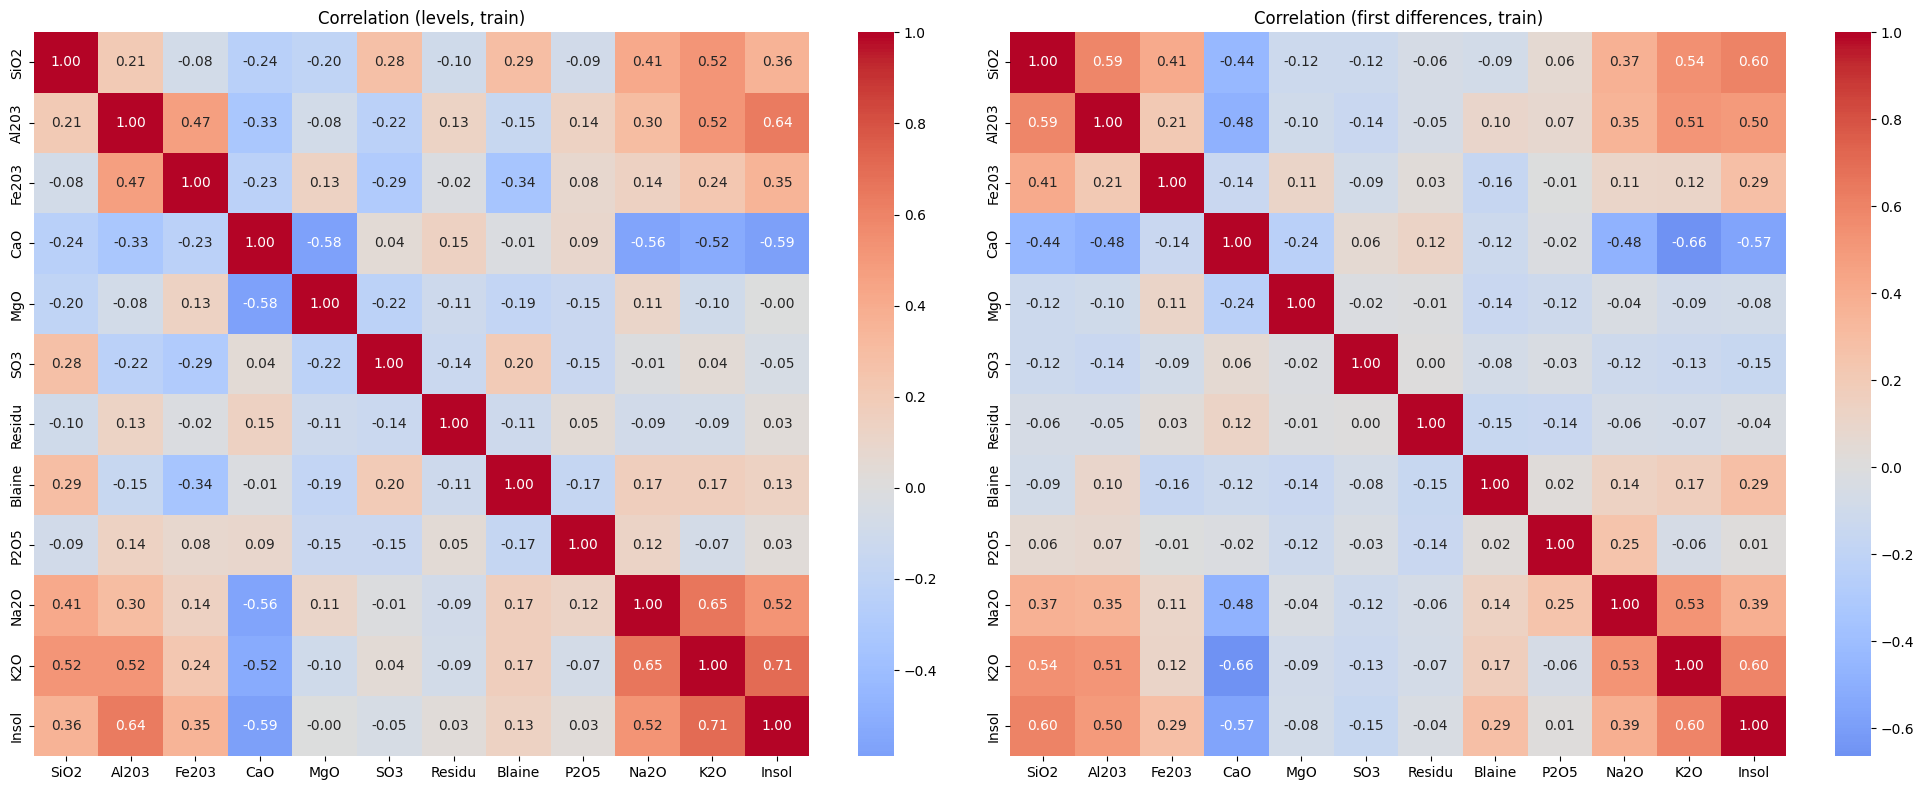

In [24]:
train_frame = X_train_imputed.copy()
train_frame[TARGET] = y_train.values

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(train_frame.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Correlation (levels, train)")
sns.heatmap(train_frame.diff().corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Correlation (first differences, train)")
plt.tight_layout()
plt.show()

## 6. Feature engineering and model selection

Lags of the 8 core oxides at 1, 2, 3, 5 and 10 days give `11 + 8 x 5 = 51` features. Lags are built on the
concatenated (imputed) train + test series: the first test rows legitimately use the end of train as their
history, because `shift()` only looks backwards. The first `MAX_LAG` train rows have no full history and are dropped.

In [25]:
X_all_imputed = pd.concat([X_train_imputed, X_test_imputed], ignore_index=True)
X_all_fe = add_lags(X_all_imputed)
n_train = len(X_train_imputed)

X_train_fe = X_all_fe.iloc[MAX_LAG:n_train].reset_index(drop=True)
y_train_fe = y_train.iloc[MAX_LAG:].reset_index(drop=True)
X_test_fe = X_all_fe.iloc[n_train:].reset_index(drop=True)
y_test_fe = y_test.reset_index(drop=True)

assert list(X_train_fe.columns) == list(X_test_fe.columns)
assert X_train_fe.isna().sum().sum() == 0 and X_test_fe.isna().sum().sum() == 0

print("X_train_fe:", X_train_fe.shape, "| X_test_fe:", X_test_fe.shape)

X_train_fe: (886, 51) | X_test_fe: (224, 51)


**Model selection** uses chronological cross-validation (`TimeSeriesSplit`) **on train only**.
Primary metric: MAE (in % Insol); RMSE and R² are reported alongside.

In [26]:
tscv = TimeSeriesSplit(n_splits=CV_SPLITS)

cv_rows = []
for name, model in candidate_models().items():
    print(f"CV: {name}")
    s = cross_validate(model, X_train_fe, y_train_fe, cv=tscv,
                       scoring={"mae": "neg_mean_absolute_error",
                                "rmse": "neg_root_mean_squared_error", "r2": "r2"})
    cv_rows.append({"Model": name, "MAE_CV": -s["test_mae"].mean(),
                    "RMSE_CV": -s["test_rmse"].mean(), "R2_CV": s["test_r2"].mean()})

cv_results = pd.DataFrame(cv_rows).sort_values("MAE_CV").reset_index(drop=True)
cv_results

CV: Linear Regression
CV: Ridge
CV: Lasso
CV: ElasticNet
CV: Decision Tree
CV: Random Forest
CV: Extra Trees
CV: Gradient Boosting
CV: Hist Gradient Boosting


,Model,MAE_CV,RMSE_CV,R2_CV
0,Gradient Boosting,0.936838,1.306407,0.462957
1,Extra Trees,0.963440,1.365530,0.418465
2,Random Forest,0.987961,1.396664,0.380582
3,Hist Gradient Boosting,1.023661,1.390407,0.392001
4,Decision Tree,1.361193,1.930621,-0.229522
5,Lasso,1.404590,2.553032,-4.440975
6,ElasticNet,1.646216,3.143511,-8.966656
7,Ridge,1.925057,3.812838,-15.744145
8,Linear Regression,1.944270,3.850824,-16.126637


## 7. Test evaluation (first and only look at the test set for model choice)

The model with the lowest CV MAE is fitted on train and compared with two naive baselines:
the train mean, and "yesterday's Insol".

In [27]:
best_name = cv_results.loc[0, "Model"]
print("Selected model (lowest CV MAE on train):", best_name)

best_model = clone(candidate_models()[best_name]).fit(X_train_fe, y_train_fe)
pred_best = best_model.predict(X_test_fe)

baseline_mean = np.full(len(y_test_fe), y_train_fe.mean())
baseline_previous = np.r_[y_train_fe.iloc[-1], y_test_fe.values[:-1]]

results_test = pd.DataFrame([
    regression_metrics(best_name, y_test_fe, pred_best),
    regression_metrics("Baseline: train mean", y_test_fe, baseline_mean),
    regression_metrics("Baseline: previous Insol", y_test_fe, baseline_previous),
])
results_test.round(3)

Selected model (lowest CV MAE on train): Gradient Boosting


,Model,MAE,RMSE,R2,% days error<=1
0,Gradient Boosting,0.620,0.785,0.454,80.804
1,Baseline: train mean,1.811,2.020,-2.619,20.089
2,Baseline: previous Insol,0.745,0.995,0.122,74.107


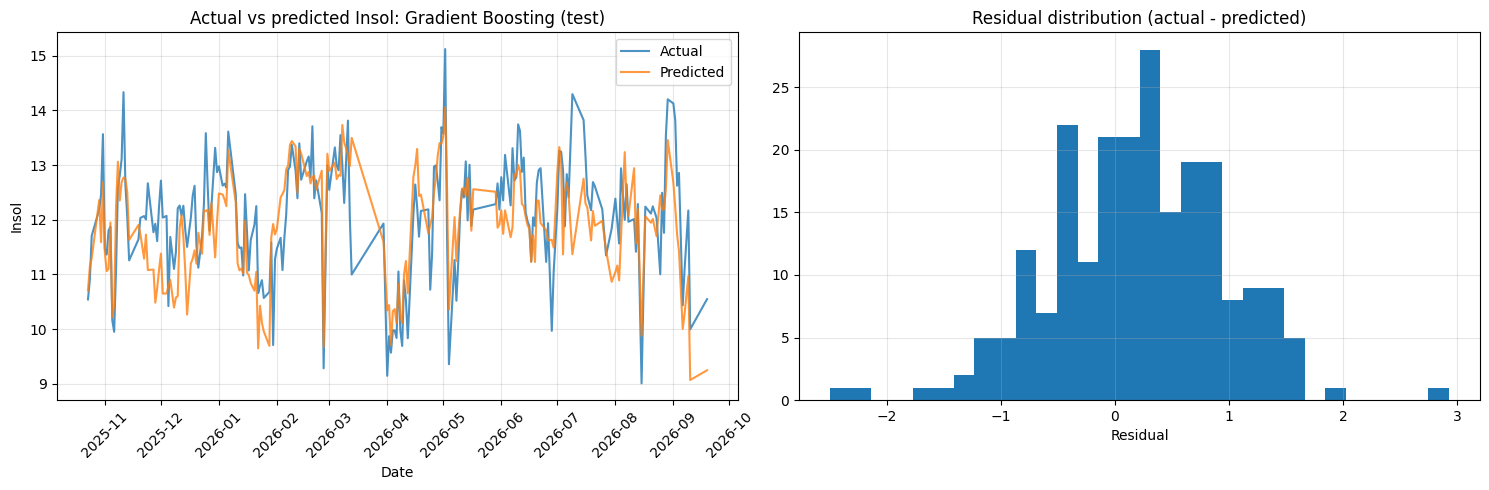

In [28]:
residual = y_test_fe.values - pred_best

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(dates_test, y_test_fe, label="Actual", alpha=0.8)
axes[0].plot(dates_test, pred_best, label="Predicted", alpha=0.8)
axes[0].set_title(f"Actual vs predicted Insol: {best_name} (test)")
axes[0].set_xlabel("Date"); axes[0].set_ylabel("Insol")
axes[0].tick_params(axis="x", rotation=45); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].hist(residual, bins=30)
axes[1].set_title("Residual distribution (actual - predicted)")
axes[1].set_xlabel("Residual"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.1 Residual bias by month

`residual = actual - prediction`. A positive monthly mean means the model under-predicts that month,
a negative one means it over-predicts. Blocks of same-signed months indicate **temporal drift**.

> This is exploratory. Do **not** use it to pick parameters.

Overall mean residual: +0.1942 (under-predicts on average)


,n,bias_Gradient Boosting,MAE_Gradient Boosting,RMSE_Gradient Boosting
Month,,,,
2025-10,6,0.264,0.456,0.549
2025-11,23,0.311,0.609,0.766
2025-12,26,0.720,0.803,0.959
2026-01,24,0.351,0.584,0.753
2026-02,21,-0.269,0.449,0.564
2026-03,11,-0.301,0.718,0.961
2026-04,25,-0.403,0.537,0.623
2026-05,18,-0.111,0.501,0.606
2026-06,24,0.324,0.559,0.701


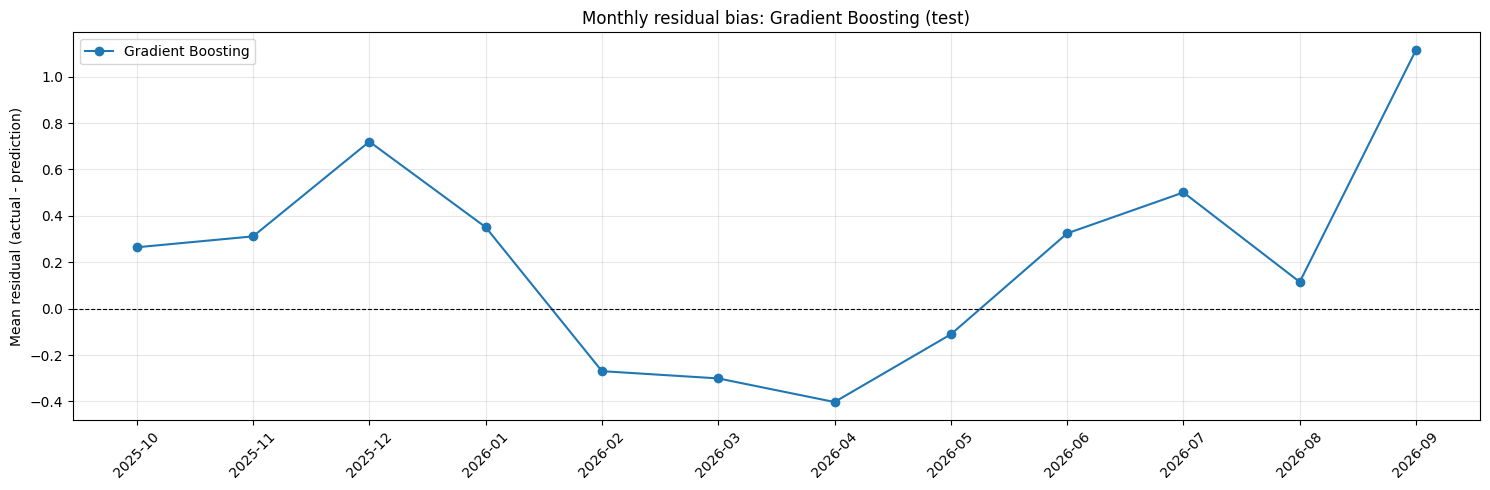

In [29]:
print(f"Overall mean residual: {residual.mean():+.4f}",
      "(under-predicts on average)" if residual.mean() > 0 else "(over-predicts on average)")

report_best = monthly_report(dates_test, y_test_fe, {best_name: pred_best})
display(report_best.round(3))
plot_monthly_bias(report_best, [best_name], f"Monthly residual bias: {best_name} (test)")

## 8. Residual correction with EWMA (baseline version)

If yesterday's actual Insol is known when predicting today, the recent residuals can be used to correct
the prediction: `final = model prediction + EWMA(past residuals)`. The residual of day *t* is only
available from day *t+1* onwards, so there is no leakage.

The EWMA `span` is chosen by `TimeSeriesSplit` **on train**. Small span = fast reaction, large span = smoother.

In [30]:
SPAN_CANDIDATES = [3, 5, 7, 10, 14, 21]

span_rows = []
for span in SPAN_CANDIDATES:
    mae_folds, rmse_folds = [], []
    for tr_idx, va_idx in TimeSeriesSplit(n_splits=CV_SPLITS).split(X_train_fe):
        X_tr, y_tr = X_train_fe.iloc[tr_idx], y_train_fe.iloc[tr_idx]
        X_va, y_va = X_train_fe.iloc[va_idx], y_train_fe.iloc[va_idx]

        fold_model = clone(best_model).fit(X_tr, y_tr)
        resid_tr = y_tr.values - fold_model.predict(X_tr)       # known before the validation block
        pred_va = sequential_residual_correction(y_va.values, fold_model.predict(X_va),
                                                 span=span, initial_residuals=resid_tr)
        mae_folds.append(mean_absolute_error(y_va, pred_va))
        rmse_folds.append(np.sqrt(mean_squared_error(y_va, pred_va)))
    span_rows.append({"span": span, "MAE_CV": np.mean(mae_folds), "RMSE_CV": np.mean(rmse_folds)})

span_results = pd.DataFrame(span_rows).sort_values("MAE_CV").reset_index(drop=True)
best_span = int(span_results.loc[0, "span"])

display(span_results)
print("Best span by CV MAE on train:", best_span)

,span,MAE_CV,RMSE_CV
0,7,0.796570,1.146525
1,5,0.798607,1.152382
2,10,0.799978,1.148098
3,14,0.805767,1.153996
4,21,0.815446,1.164151
5,3,0.830003,1.188113


Best span by CV MAE on train: 7


In [31]:
train_residuals = y_train_fe.values - best_model.predict(X_train_fe)
pred_ewma_v1 = sequential_residual_correction(y_test_fe.values, pred_best,
                                              span=best_span, initial_residuals=train_residuals)

label_v1 = f"{best_name} + EWMA (span={best_span})"
comparison_v1 = pd.DataFrame([
    regression_metrics(best_name, y_test_fe, pred_best),
    regression_metrics(label_v1, y_test_fe, pred_ewma_v1),
    regression_metrics("Baseline: train mean", y_test_fe, baseline_mean),
    regression_metrics("Baseline: previous Insol", y_test_fe, baseline_previous),
])
display(comparison_v1.round(3))

mae_before, mae_after = comparison_v1.loc[0, "MAE"], comparison_v1.loc[1, "MAE"]
rmse_before, rmse_after = comparison_v1.loc[0, "RMSE"], comparison_v1.loc[1, "RMSE"]
print(f"MAE : {mae_before:.4f} -> {mae_after:.4f}  ({(mae_before - mae_after) / mae_before * 100:+.2f}% reduction)")
print(f"RMSE: {rmse_before:.4f} -> {rmse_after:.4f}  ({(rmse_before - rmse_after) / rmse_before * 100:+.2f}% reduction)")

,Model,MAE,RMSE,R2,% days error<=1
0,Gradient Boosting,0.620,0.785,0.454,80.804
1,Gradient Boosting + EWMA (span=7),0.518,0.683,0.586,88.393
2,Baseline: train mean,1.811,2.020,-2.619,20.089
3,Baseline: previous Insol,0.745,0.995,0.122,74.107


MAE : 0.6203 -> 0.5179  (+16.50% reduction)
RMSE: 0.7847 -> 0.6830  (+12.97% reduction)


,n,bias_no correction,MAE_no correction,RMSE_no correction,bias_EWMA,MAE_EWMA,RMSE_EWMA
Month,,,,,,,
2025-10,6,0.264,0.456,0.549,0.304,0.409,0.517
2025-11,23,0.311,0.609,0.766,0.175,0.536,0.661
2025-12,26,0.720,0.803,0.959,0.356,0.611,0.750
2026-01,24,0.351,0.584,0.753,0.106,0.413,0.634
2026-02,21,-0.269,0.449,0.564,-0.116,0.358,0.457
2026-03,11,-0.301,0.718,0.961,-0.177,0.797,0.987
2026-04,25,-0.403,0.537,0.623,-0.185,0.435,0.535
2026-05,18,-0.111,0.501,0.606,-0.030,0.484,0.609
2026-06,24,0.324,0.559,0.701,0.126,0.479,0.614


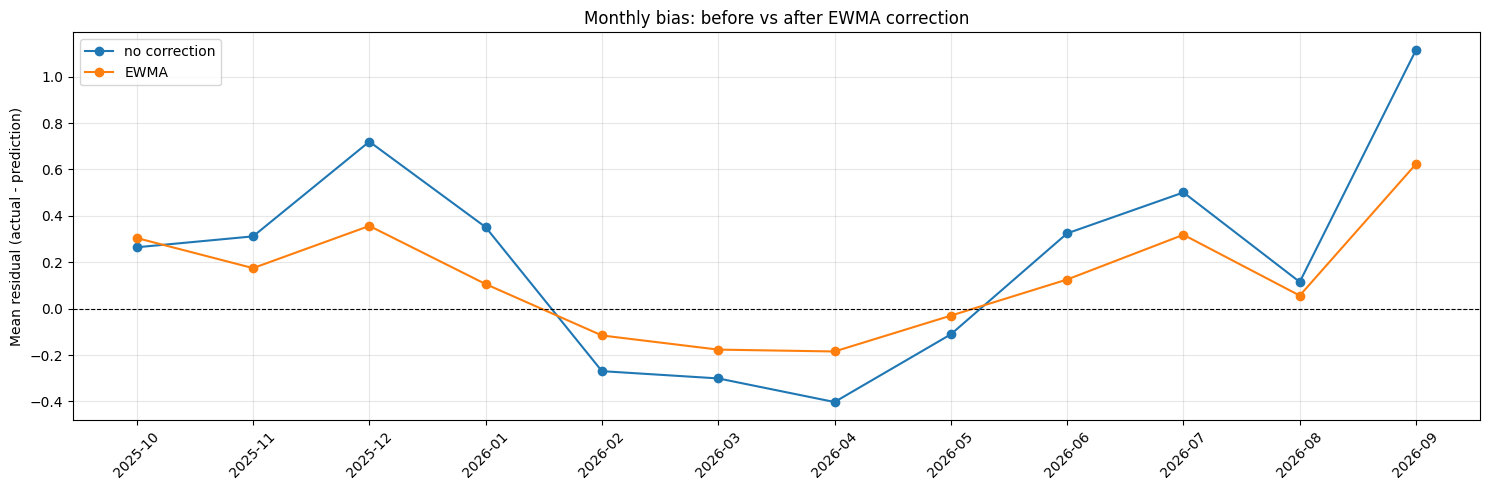

In [32]:
report_v1 = monthly_report(dates_test, y_test_fe, {"no correction": pred_best, "EWMA": pred_ewma_v1})
display(report_v1.round(3))
plot_monthly_bias(report_v1, ["no correction", "EWMA"], "Monthly bias: before vs after EWMA correction")

## 9. Tuning and improved residual correction

Four changes relative to section 8:

1. **Correction function.** `sequential_residual_correction` stores `actual - corrected prediction`, so for a constant bias *b* it only converges to *b/2*. `ewma_correction` uses the **raw** model residual and can close the full bias (simulation below).
2. **Tuning** of Ridge / Lasso / ElasticNet with `TimeSeriesSplit` on train, and original features vs. original + lags.
3. **Out-of-fold residuals** to choose `span` and a shrinkage factor `k` (`k = 0` means "no correction", so not correcting is also a candidate).
4. **Significance tests** (Wilcoxon + block bootstrap) and **ACF of residuals** before vs. after.

`LAB_DELAY_DAYS` is how many days late the actual Insol arrives (0 = yesterday's value is known today).

In [33]:
LAB_DELAY_DAYS = 0

# Sanity check: the model is always 1.0 too low, with a little noise
rng = np.random.default_rng(0)
p_sim = np.full(300, 5.0)
y_sim = 6.0 + rng.normal(0, 0.3, 300)

old_c = sequential_residual_correction(y_sim, p_sim, span=7) - p_sim
new_c = ewma_correction(y_sim - p_sim, span=7)

print("True bias                          : 1.00")
print(f"Mean correction, sequential version: {old_c[50:].mean():.2f}")
print(f"Mean correction, raw-residual version: {new_c[50:].mean():.2f}")

True bias                          : 1.00
Mean correction, sequential version: 0.49
Mean correction, raw-residual version: 0.99


### 9.1 Tune linear models

In [34]:
tscv_tune = TimeSeriesSplit(n_splits=CV_SPLITS)

tuning_rows, searches = [], {}
for name in TUNING_CANDIDATES:
    searches[name] = tune_linear(name, X_train_fe, y_train_fe, tscv_tune)
    tuning_rows.append({
        "Model": name,
        "MAE_CV": -searches[name].best_score_,
        "Best parameters": {k.replace("m__", ""): round(float(v), 5)
                            for k, v in searches[name].best_params_.items()},
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values("MAE_CV").reset_index(drop=True)
tuned_name = tuning_results.loc[0, "Model"]

print(f"Reference: untuned Lasso (alpha=0.01) MAE_CV = {cv_results.set_index('Model').loc['Lasso', 'MAE_CV']:.4f}")
display(tuning_results)
print("Best family after tuning:", tuned_name)

Reference: untuned Lasso (alpha=0.01) MAE_CV = 1.4046


,Model,MAE_CV,Best parameters
0,ElasticNet,0.801617,"{'alpha': 0.03039, 'l1_ratio': 0.9}"
1,Lasso,0.801709,{'alpha': 0.03039}
2,Ridge,1.199638,{'alpha': 1000.0}


Best family after tuning: ElasticNet


**Original features vs. original + lags.** Parsimony rule: use the lag set only if it improves CV MAE by at least 1 %.

In [35]:
cols_original = [c for c in X_train_fe.columns if "_lag" not in c]
cols_all = list(X_train_fe.columns)

search_original = tune_linear(tuned_name, X_train_fe[cols_original], y_train_fe, tscv_tune)
search_with_lags = tune_linear(tuned_name, X_train_fe[cols_all], y_train_fe, tscv_tune)
mae_original, mae_with_lags = -search_original.best_score_, -search_with_lags.best_score_

display(pd.DataFrame([
    {"Feature set": f"Original only ({len(cols_original)})", "MAE_CV": mae_original},
    {"Feature set": f"Original + lags ({len(cols_all)})", "MAE_CV": mae_with_lags},
]))

if mae_with_lags < 0.99 * mae_original:
    tuned_cols, tuned_search = cols_all, search_with_lags
    print("Selected feature set: original + lags")
else:
    tuned_cols, tuned_search = cols_original, search_original
    print("Selected feature set: original only (lags do not improve accuracy by more than 1 %)")

tuned_model = tuned_search.best_estimator_            # already fitted on the whole train set
pred_tuned = tuned_model.predict(X_test_fe[tuned_cols])

print("Best parameters:", {k.replace("m__", ""): float(v) for k, v in tuned_search.best_params_.items()})
print(f"MAE_CV of the tuned model: {-tuned_search.best_score_:.4f}")

coef = getattr(tuned_model.named_steps["m"], "coef_", None)
if coef is not None:
    coef_s = pd.Series(coef, index=tuned_cols)
    print(f"Zero coefficients: {(coef_s == 0).sum()} of {len(coef_s)}")
    display(coef_s.reindex(coef_s.abs().sort_values(ascending=False).index).head(10).to_frame("coefficient (z-scale)"))

,Feature set,MAE_CV
0,Original only (11),0.798021
1,Original + lags (51),0.801617


Selected feature set: original only (lags do not improve accuracy by more than 1 %)
Best parameters: {'alpha': 0.021261123338996556, 'l1_ratio': 0.9}
MAE_CV of the tuned model: 0.7980
Zero coefficients: 2 of 11


,coefficient (z-scale)
CaO,-0.802206
Al203,0.694132
K2O,0.442998
MgO,-0.304412
Blaine,0.292178
Fe203,0.187827
Residu,0.107722
P2O5,0.023846
SO3,0.020529
SiO2,0.000000


### 9.2 Out-of-fold residuals, then choose `span` and `k`

Each `TimeSeriesSplit` fold trains on the past only and predicts the next block. Stitched together, these
blocks form an honest prediction series on which the correction is simulated day by day.
The **test set is not touched**.

In [36]:
y_arr = y_train_fe.values.astype(float)
X_tuned_train = X_train_fe[tuned_cols]

oof_pred = np.full(len(y_arr), np.nan)
for idx_tr, idx_va in tscv_tune.split(X_tuned_train):
    fold_model = clone(tuned_model).fit(X_tuned_train.iloc[idx_tr], y_arr[idx_tr])
    oof_pred[idx_va] = fold_model.predict(X_tuned_train.iloc[idx_va])

has_oof = ~np.isnan(oof_pred)
oof_resid = y_arr[has_oof] - oof_pred[has_oof]          # raw model residuals, in time order

print("Out-of-fold points:", has_oof.sum())
print(f"OOF MAE (no correction): {np.mean(np.abs(oof_resid)):.4f}")
print(f"OOF bias               : {oof_resid.mean():.4f}")

Out-of-fold points: 735
OOF MAE (no correction): 0.7980
OOF bias               : 0.2398


In [37]:
K_CANDIDATES = [0.0, 0.25, 0.5, 0.75, 1.0]

rows = []
for span in SPAN_CANDIDATES:
    c = ewma_correction(oof_resid, span, LAB_DELAY_DAYS)
    for k in K_CANDIDATES:
        err = oof_resid - k * c
        rows.append({"span": span, "k": k, "MAE_OOF": np.mean(np.abs(err)),
                     "RMSE_OOF": np.sqrt(np.mean(err ** 2))})

sk_results = pd.DataFrame(rows).sort_values("MAE_OOF").reset_index(drop=True)
display(sk_results.head(10))

span_v2, k_v2 = int(sk_results.loc[0, "span"]), float(sk_results.loc[0, "k"])
print(f"Selected: span={span_v2}, k={k_v2}")
print(f"MAE OOF: {np.mean(np.abs(oof_resid)):.4f} (no correction) -> {sk_results.loc[0, 'MAE_OOF']:.4f}")
if k_v2 == 0:
    print("Note: k=0 was selected, meaning the EWMA correction does not help on train.")

,span,k,MAE_OOF,RMSE_OOF
0,7,0.75,0.710961,1.101353
1,5,0.75,0.711513,1.108049
2,10,0.75,0.713125,1.097841
3,5,0.50,0.713956,1.103185
4,14,0.75,0.715657,1.096716
5,7,0.50,0.715786,1.103183
6,3,0.50,0.715810,1.107791
7,21,0.75,0.718424,1.097610
8,10,0.50,0.719433,1.104498
9,3,0.75,0.722238,1.128749


Selected: span=7, k=0.75
MAE OOF: 0.7980 (no correction) -> 0.7110


### 9.3 Test evaluation (single use)

The initial residual history for test is the **last out-of-fold** residuals of train, not in-sample ones.
The correction for day *t* only uses residuals up to *t - 1 - delay*.

In [38]:
y_te = y_test_fe.values.astype(float)

history = oof_resid[-60:]                                 # honest history before the test period
test_resid_raw = y_te - pred_tuned
c_all = ewma_correction(np.r_[history, test_resid_raw], span_v2, LAB_DELAY_DAYS)
pred_final_v2 = pred_tuned + k_v2 * c_all[len(history):]

comparison_v2 = pd.DataFrame([
    regression_metrics(f"{best_name} (default parameters)", y_te, pred_best),
    regression_metrics(f"{tuned_name} tuned", y_te, pred_tuned),
    regression_metrics(f"{tuned_name} tuned + EWMA (span={span_v2}, k={k_v2})", y_te, pred_final_v2),
    regression_metrics(label_v1 + " [section 8]", y_te, pred_ewma_v1),
    regression_metrics("Baseline: train mean", y_te, baseline_mean),
    regression_metrics("Baseline: previous Insol", y_te, baseline_previous),
])
display(comparison_v2.round(3))

m0, m1, m2 = comparison_v2.loc[0, "MAE"], comparison_v2.loc[1, "MAE"], comparison_v2.loc[2, "MAE"]
print(f"MAE: default {m0:.4f} -> tuned {m1:.4f} -> tuned + EWMA {m2:.4f}")
print(f"Total reduction vs default: {(m0 - m2) / m0 * 100:.2f}%   |   from EWMA alone: {(m1 - m2) / m1 * 100:.2f}%")

,Model,MAE,RMSE,R2,% days error<=1
0,Gradient Boosting (default parameters),0.620,0.785,0.454,80.804
1,ElasticNet tuned,0.700,0.863,0.339,78.125
2,"ElasticNet tuned + EWMA (span=7, k=0.75)",0.505,0.670,0.602,91.518
3,Gradient Boosting + EWMA (span=7) [section 8],0.518,0.683,0.586,88.393
4,Baseline: train mean,1.811,2.020,-2.619,20.089
5,Baseline: previous Insol,0.745,0.995,0.122,74.107


MAE: default 0.6203 -> tuned 0.7000 -> tuned + EWMA 0.5052
Total reduction vs default: 18.55%   |   from EWMA alone: 27.82%


### 9.4 Is the improvement significant?

`d = |error without EWMA| - |error with EWMA|` per day (positive = EWMA better). Wilcoxon assumes independent days,
but residuals are autocorrelated, so its p-value tends to be optimistic. The **block bootstrap** (10-day blocks)
respects the dependence and is the better number to quote.

In [39]:
d = np.abs(y_te - pred_tuned) - np.abs(y_te - pred_final_v2)
print(f"Mean MAE difference (positive = EWMA better): {d.mean():.4f}")

try:
    print(f"Wilcoxon (one-sided): p = {wilcoxon(d, alternative='greater').pvalue:.4f}")
except ValueError as err:
    print("Wilcoxon could not be computed:", err)

rng = np.random.default_rng(RANDOM_STATE)
block, n_days = 10, len(d)
n_blocks = int(np.ceil(n_days / block))
boot = np.empty(5000)
for b in range(5000):
    starts = rng.integers(0, n_days - block + 1, n_blocks)
    boot[b] = np.concatenate([d[s:s + block] for s in starts])[:n_days].mean()

lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Block bootstrap 95% CI of the MAE difference: [{lo:.4f}, {hi:.4f}]")
print("Significant improvement" if lo > 0 else "Interval includes 0: improvement not proven")

Mean MAE difference (positive = EWMA better): 0.1948
Wilcoxon (one-sided): p = 0.0000
Block bootstrap 95% CI of the MAE difference: [0.1051, 0.3024]
Significant improvement


### 9.5 Residual autocorrelation before vs. after

If the correction captures temporal structure, residual autocorrelation should fall.
Ljung-Box: a small p-value means autocorrelation remains.

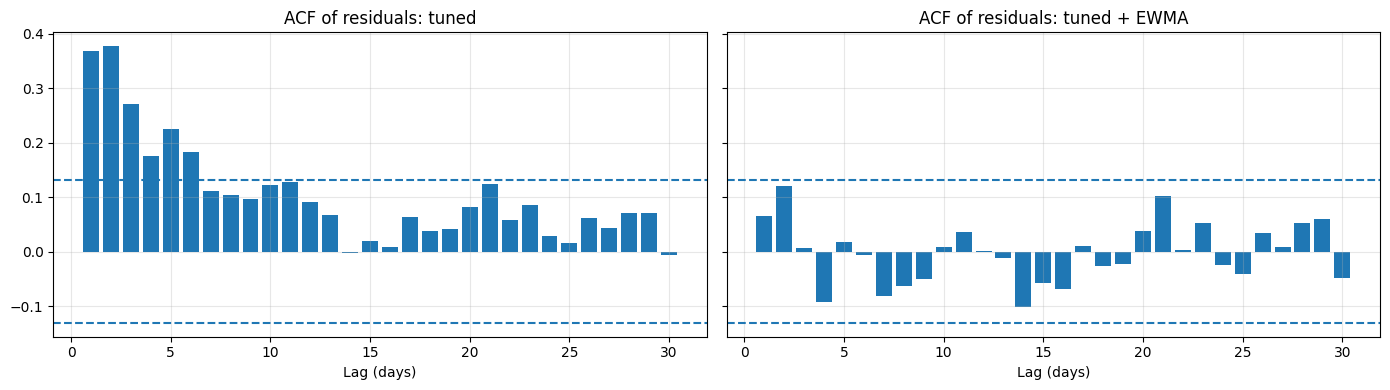

,Lag,Ljung-Box p (tuned),Ljung-Box p (tuned + EWMA)
0,5,8.474821e-20,0.270754
1,10,1.380645e-20,0.485627
2,20,8.055056e-18,0.780139


In [40]:
res_before, res_after = y_te - pred_tuned, y_te - pred_final_v2
conf = 1.96 / np.sqrt(len(y_te))

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, res, title in zip(axes, [res_before, res_after], ["ACF of residuals: tuned", "ACF of residuals: tuned + EWMA"]):
    ax.bar(range(1, 31), acf_manual(res, 30)[1:])
    ax.axhline(conf, linestyle="--"); ax.axhline(-conf, linestyle="--")
    ax.set_title(title); ax.set_xlabel("Lag (days)"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Lag": [5, 10, 20],
    "Ljung-Box p (tuned)": list(ljung_box(res_before).values()),
    "Ljung-Box p (tuned + EWMA)": list(ljung_box(res_after).values()),
}))

,n,bias_Gradient Boosting,MAE_Gradient Boosting,RMSE_Gradient Boosting,bias_tuned,MAE_tuned,RMSE_tuned,bias_tuned + EWMA,MAE_tuned + EWMA,RMSE_tuned + EWMA
Month,,,,,,,,,,
2025-10,6,0.264,0.456,0.549,0.494,0.520,0.679,0.347,0.426,0.552
2025-11,23,0.311,0.609,0.766,0.531,0.662,0.836,0.219,0.499,0.628
2025-12,26,0.720,0.803,0.959,0.940,0.982,1.112,0.212,0.492,0.654
2026-01,24,0.351,0.584,0.753,0.515,0.628,0.698,0.015,0.301,0.462
2026-02,21,-0.269,0.449,0.564,0.184,0.447,0.545,0.003,0.415,0.504
2026-03,11,-0.301,0.718,0.961,0.257,0.627,0.781,0.115,0.703,0.814
2026-04,25,-0.403,0.537,0.623,-0.143,0.439,0.537,-0.015,0.425,0.535
2026-05,18,-0.111,0.501,0.606,0.323,0.575,0.716,0.192,0.535,0.631
2026-06,24,0.324,0.559,0.701,0.881,0.964,1.085,0.141,0.479,0.599


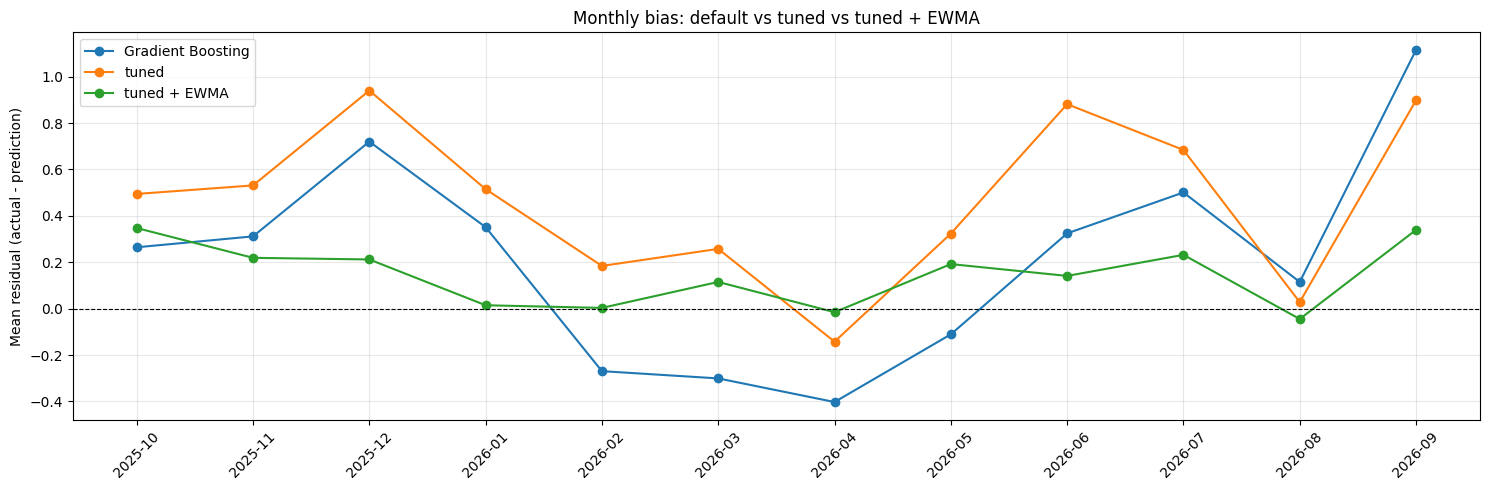

In [41]:
report_v2 = monthly_report(dates_test, y_test_fe, {
    best_name: pred_best, "tuned": pred_tuned, "tuned + EWMA": pred_final_v2})
display(report_v2.round(3))
plot_monthly_bias(report_v2, [best_name, "tuned", "tuned + EWMA"], "Monthly bias: default vs tuned vs tuned + EWMA")

### 9.6 Notes

- Model, feature set, `alpha` / `l1_ratio`, `span` and `k` are all chosen on **train** (chronological CV and out-of-fold residuals). The test set is evaluated once.
- The monthly residual analyses are **exploratory**; never use them to choose parameters.
- EWMA correction is only valid if the previous days' actual Insol is known at prediction time. Set `LAB_DELAY_DAYS` accordingly and re-run this section.
- If the bootstrap interval in 9.4 includes 0, report that the EWMA improvement is **not proven significant**.

## 10. Huber regression: final model and final measurement

Huber loss is more robust to spikes in Insol. It is trained on **train only** and tested on **test**, with the
baseline EWMA correction at the fixed `EWMA_SPAN`. The best CV model from section 7 is included for reference.

In [42]:
# Best CV model + EWMA with the fixed span
pred_best_ewma = sequential_residual_correction(
    y_test_fe.values, pred_best, span=EWMA_SPAN,
    initial_residuals=y_train_fe.values - best_model.predict(X_train_fe))

# Huber: fit on TRAIN, evaluate on TEST
huber = make_huber().fit(X_train_fe, y_train_fe)
huber_train_residuals = y_train_fe.values - huber.predict(X_train_fe)
pred_huber = huber.predict(X_test_fe)
pred_huber_ewma = sequential_residual_correction(
    y_test_fe.values, pred_huber, span=EWMA_SPAN, initial_residuals=huber_train_residuals)

final_metrics = pd.DataFrame([
    regression_metrics(f"{best_name} + EWMA ({EWMA_SPAN})", y_test_fe, pred_best_ewma),
    regression_metrics("Huber", y_test_fe, pred_huber),
    regression_metrics(f"Huber + EWMA ({EWMA_SPAN})", y_test_fe, pred_huber_ewma),
]).round(3)
final_metrics

,Model,MAE,RMSE,R2,% days error<=1
0,Gradient Boosting + EWMA (7),0.518,0.683,0.586,88.393
1,Huber,0.636,0.782,0.457,81.696
2,Huber + EWMA (7),0.509,0.664,0.610,90.179


## 11. Final figure: actual vs. predicted

Huber + EWMA on the test period, with the +/-`TOLERANCE` band and the days that fall outside it.

Huber + EWMA (7): MAE=0.509  RMSE=0.664  R2=0.610  error<=1: 90.2%  (22 days outside)
Std of Insol in test = 1.062


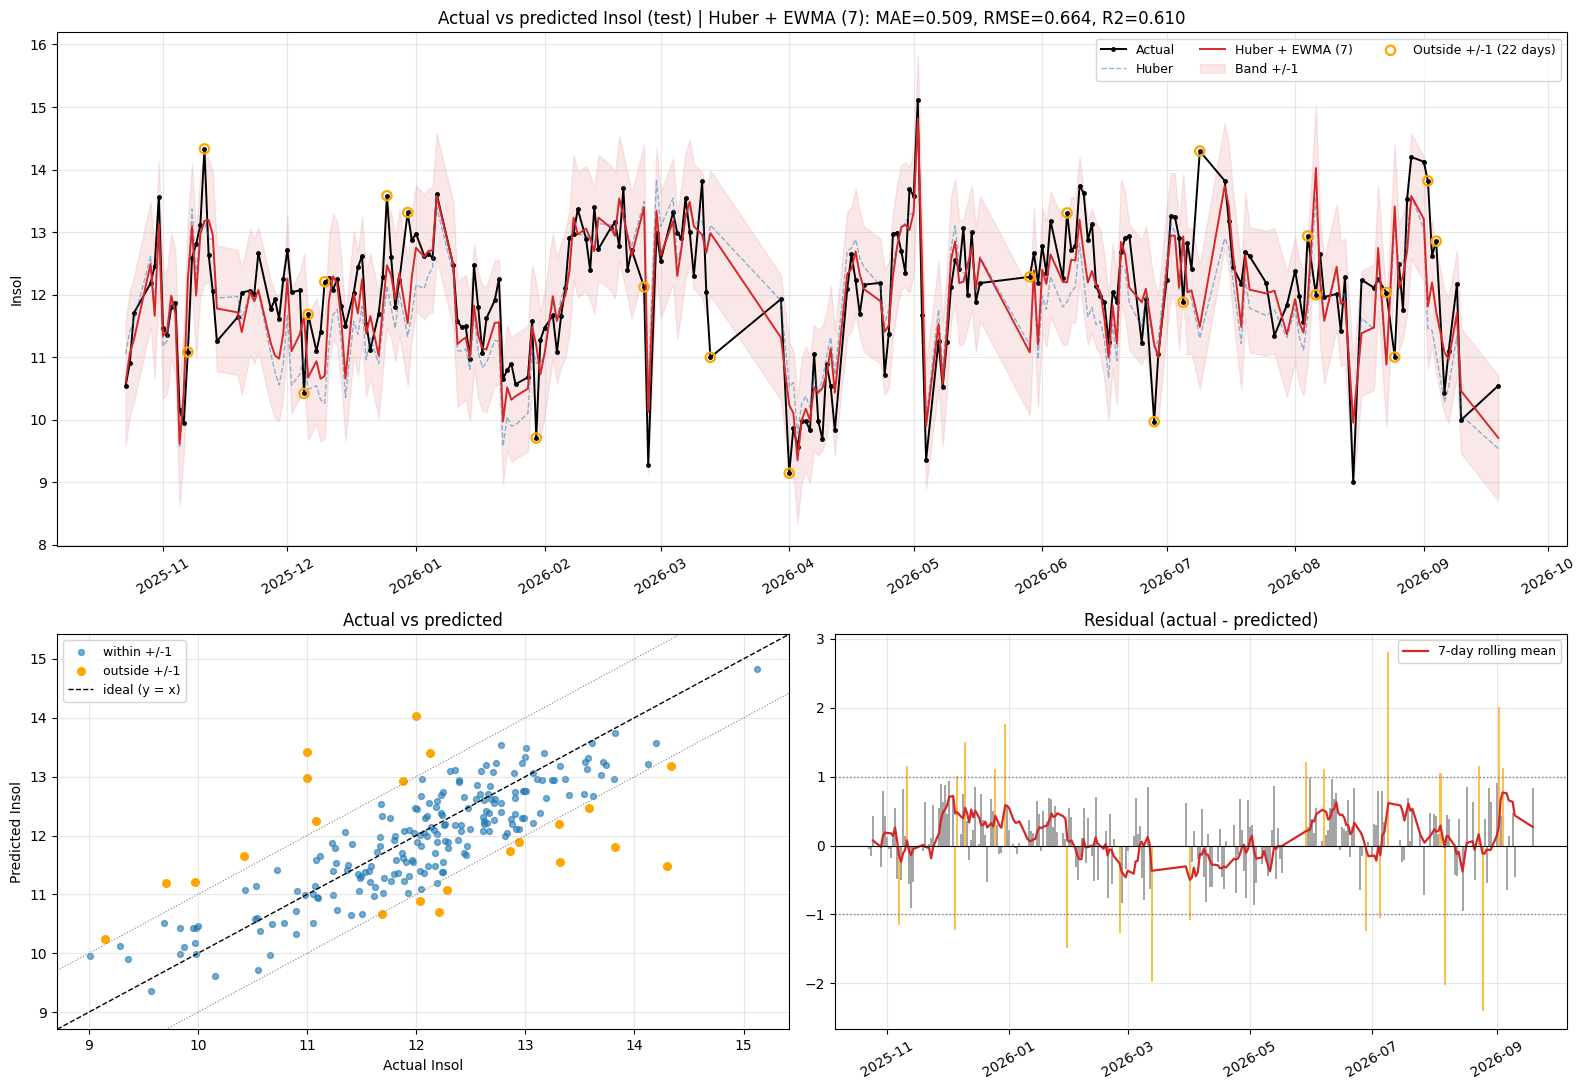

Days furthest from the actual value:


,date,actual,predicted,error
185,2026-07-09,14.296,11.488,2.807
210,2026-08-25,11.003,13.411,-2.407
199,2026-08-06,11.998,14.025,-2.027
216,2026-09-02,13.820,11.812,2.008
109,2026-03-13,10.999,12.985,-1.986
53,2025-12-30,13.314,11.544,1.770
36,2025-12-10,12.208,10.703,1.505
77,2026-01-30,9.709,11.194,-1.485
97,2026-02-25,12.124,13.400,-1.276
176,2026-06-28,9.969,11.210,-1.241


In [43]:
worst_days = plot_actual_vs_predicted(
    dates_test, y_test_fe.values, pred_huber_ewma, pred_huber,
    label=f"Huber + EWMA ({EWMA_SPAN})",
    save_as=OUTPUT_DIR / f"actual_vs_predicted_{SILO}.png")

print("Days furthest from the actual value:")
worst_days

## 12. Inference

Lags and the correction come from the **daily history**, so predictions are most accurate when
`NEW_DAILY_FILE` contains every day up to *yesterday*.

> **Staleness warning.** If the last known day is more than 3 days before the target day, lags and EWMA are
> out of date and the prediction should be treated as a rough estimate.

In [44]:
def build_history(new_daily_file=None):
    """Imputed feature history, matching Insol history and the last known date (optionally + new days)."""
    X_hist = X_all_imputed.reset_index(drop=True).copy()
    y_hist = df[TARGET].astype(float).tolist()
    last_date = df["Tanggal"].max()

    if new_daily_file is not None:
        new = pd.read_excel(new_daily_file)
        new.columns = new.columns.str.strip()
        new["Tanggal"] = pd.to_datetime(new["Tanggal"])
        for c in FEATURES + [TARGET]:
            new[c] = pd.to_numeric(new[c], errors="coerce")
        if APPLY_DOMAIN_RULES:
            new = apply_domain_rules(new)
        new = new[new["Tanggal"] > last_date].sort_values("Tanggal").reset_index(drop=True)
        assert new[TARGET].notna().all(), "Empty Insol in the new daily file"
        X_hist = pd.concat([X_hist, impute(new, scaler_imp, knn_imputer)], ignore_index=True)
        y_hist += new[TARGET].tolist()
        last_date = new["Tanggal"].max()
        print(f"Added {len(new)} new days (up to {last_date.date()})")

    assert len(X_hist) == len(y_hist), "X_hist and y_hist differ in length"
    return X_hist, y_hist, last_date


def warn_if_stale(last_date, target_date, max_gap=3):
    gap = (pd.Timestamp(target_date) - last_date).days
    print(f"Actual history ends on {last_date.date()} (gap {gap} days)")
    if gap > max_gap:
        print("WARNING: the actual Insol history is stale. Add the missing days so lags and EWMA stay accurate.")

### 12.1 Next-day prediction

The Huber model is **retrained on all known days** (train + test + optional new data), then corrected with the EWMA of its residuals.

In [45]:
def predict_next_day(components, target_date, actual_insol=None, new_daily_file=None):
    """components: dict with the 11 features of the target day (np.nan for anything not measured)."""
    X_hist, y_hist, last_date = build_history(new_daily_file)
    n_known = len(y_hist)

    x_new = impute(pd.DataFrame([components]), scaler_imp, knn_imputer)
    X_full = pd.concat([X_hist, x_new], ignore_index=True)
    F = add_lags(X_full)

    cols = list(X_train_fe.columns)
    X_fit, y_fit = F.iloc[MAX_LAG:n_known][cols], pd.Series(y_hist).iloc[MAX_LAG:]
    model = make_huber().fit(X_fit, y_fit)
    offset = latest_ewma_offset(y_fit.values - model.predict(X_fit), EWMA_SPAN)

    x_target = F.iloc[[-1]][cols]
    assert x_target.isna().sum().sum() == 0, "NaN in the target features"
    pred_model = float(model.predict(x_target)[0])
    pred_final = pred_model + offset

    print(f"Insol prediction for {target_date}")
    print(f"  Huber only            : {pred_model:.3f}")
    print(f"  EWMA correction (span {EWMA_SPAN}): {offset:+.3f}")
    print(f"  Final                 : {pred_final:.3f}")
    warn_if_stale(last_date, target_date)
    if actual_insol is not None:
        print(f"  Actual: {actual_insol:.3f} | actual - prediction: {actual_insol - pred_final:+.3f}")
    return pred_final

In [ ]:
# Illustrative values only: replace with the real composition of the target day.
# Use np.nan for anything not measured (imputed with the KNN imputer fitted on train).
example_components = {
    "SiO2": 20.3, "Al203": 6.1, "Fe203": 2.9, "CaO": 58.9, "MgO": 1.9, "SO3": 1.5,
    "Residu": 8.7, "Blaine": 458.0, "P2O5": np.nan, "Na2O": 0.41, "K2O": 0.57,
}

_ = predict_next_day(example_components, target_date="2026-10-20", actual_insol=None, new_daily_file=NEW_DAILY_FILE)

### 12.2 Hourly (per-row) prediction from a QC CSV

Each row is predicted from **that hour's oxides + the daily lag history + the EWMA correction** (identical for
all hours of the day). A row's value means *"the daily Insol to expect if the whole day looked like this hour"*,
not an hourly Insol. Compare with the lab value only through the **mean** of the rows.

The Huber model from section 10 is used **without retraining**; the correction is the EWMA of its residuals over
the whole known history. Only rows where all 8 core oxides are present are predicted; MgO, Residu and P2O5 are
KNN-imputed when missing. The source CSV is **never overwritten**.

In [46]:
def predict_hourly(csv_path, output_path=None, new_daily_file=None, actual_insol=None):
    X_hist, y_hist, last_date = build_history(new_daily_file)
    cols = list(X_train_fe.columns)

    # EWMA correction from the model's residuals over the whole known history
    F_hist = add_lags(X_hist)
    Xh, yh = F_hist.iloc[MAX_LAG:][cols], pd.Series(y_hist).iloc[MAX_LAG:]
    offset = latest_ewma_offset(yh.values - huber.predict(Xh), EWMA_SPAN)

    q = pd.read_csv(csv_path).rename(columns={"Al2O3": "Al203", "Fe2O3": "Fe203"})
    q["Time"] = pd.to_datetime(q["SamplingLocalTime"])
    for c in FEATURES:
        q[c] = pd.to_numeric(q[c], errors="coerce") if c in q.columns else np.nan
    complete = q[LAG_FEATURES].notna().all(axis=1)
    print(f"Rows in CSV: {len(q)} | predicted: {complete.sum()} | skipped (missing core oxides): {(~complete).sum()}")
    Q = q[complete].reset_index(drop=True)
    Q_imp = impute(Q, scaler_imp, knn_imputer)

    # Same lag values for every hour of the day: they come from previous days
    lag_vec = {f"{c}_lag{L}": X_hist[c].iloc[-L] for c in LAG_FEATURES for L in LAG_LIST}
    X_row = pd.concat([Q_imp, pd.DataFrame([lag_vec] * len(Q_imp))], axis=1)[cols]
    assert X_row.isna().sum().sum() == 0, "NaN in the features"

    result = pd.concat([Q[["Time"]].assign(Time=Q["Time"].dt.strftime("%H:%M")), Q_imp], axis=1)
    result["Pred_Huber"] = huber.predict(X_row)
    result["Pred_Final"] = result["Pred_Huber"] + offset

    print(f"EWMA correction (span {EWMA_SPAN}): {offset:+.3f}")
    print(f"Mean / median / min / max: {result['Pred_Final'].mean():.3f} / {result['Pred_Final'].median():.3f} / "
          f"{result['Pred_Final'].min():.3f} / {result['Pred_Final'].max():.3f}")
    warn_if_stale(last_date, Q["Time"].dt.normalize().iloc[0])
    if actual_insol is not None:
        print(f"Lab Insol: {actual_insol:.3f} | lab - mean of rows: {actual_insol - result['Pred_Final'].mean():+.3f}")
    if output_path is not None:
        result.round(4).to_csv(output_path, index=False)
        print("Saved:", output_path)
    return result

In [47]:
if HOURLY_CSV.exists():
    hourly_result = predict_hourly(HOURLY_CSV, OUTPUT_DIR / f"{HOURLY_CSV.stem}_predicted.csv",
                                   new_daily_file=NEW_DAILY_FILE)
    display(hourly_result.round(3))
else:
    print(f"{HOURLY_CSV} not found: skipping hourly prediction.")

data/QC_hourly.csv not found: skipping hourly prediction.


## 13. Save the model (optional)

Stores everything needed to predict later without re-running the notebook: the Huber model, the imputer,
the column order, the lag settings, the span and the daily history that lags and EWMA depend on.

In [48]:
X_hist, y_hist, last_date = build_history(NEW_DAILY_FILE)

bundle = {
    "model": huber,                          # StandardScaler + Huber, fitted on train
    "feature_columns": list(X_train_fe.columns),
    "base_columns": FEATURES,
    "lag_features": LAG_FEATURES,
    "lag_list": LAG_LIST,
    "span": EWMA_SPAN,
    "scaler_imp": scaler_imp,
    "imputer": knn_imputer,
    "X_hist": X_hist,                        # imputed daily history
    "y_hist": y_hist,                        # actual Insol history
    "last_date": last_date,
}

MODEL_PATH = OUTPUT_DIR / f"model_{SILO}_huber_ewma{EWMA_SPAN}.joblib"
joblib.dump(bundle, MODEL_PATH)
print("Model saved:", MODEL_PATH)

Model saved: outputs/model_insilo1_huber_ewma7.joblib
